# Forecasting Term-Deposit Subscriptions from Prior Campaign Data

**Author:** Teja Manjusree Koduru, M.Sc. Big Data & Business Analytics, FOM Essen

**Business question:** A Portuguese bank runs telephone campaigns for term deposits. Which customers are most likely to subscribe, so the call centre can contact them first and spend less effort on unlikely customers?

**Data:** UCI Bank Marketing dataset (`bank-additional-full.csv`), 41,188 contacts, 20 input features, target `y` (subscribed yes/no).

**Approach**
1. Data quality checks (missing values, "unknown" categories, duplicates)
2. Exploratory analysis and statistical tests (t-test, ANOVA)
3. Leakage-free modelling: `duration` is excluded, and the train/test split happens **before** any scaling or resampling
4. Class imbalance (about 8 : 1) handled with class weights; SMOTE-ENN as an optional comparison
5. Model comparison with ROC AUC, precision, recall, F1 and 5-fold cross-validation
6. Business translation: how many subscribers the bank reaches by calling only the highest-scored customers

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 2. Load the data

In [2]:
df = pd.read_csv("data/bank-additional-full.csv", sep=";")
print("Shape:", df.shape)
df.head()

Shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 3. Data quality checks

In [3]:
print("Missing values (NaN):", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

unknown_counts = (df.select_dtypes("object") == "unknown").sum()
print("\n'unknown' values per categorical column:")
print(unknown_counts[unknown_counts > 0])

df = df.drop_duplicates(keep="first").reset_index(drop=True)
print("\nShape after removing duplicates:", df.shape)

Missing values (NaN): 0
Duplicate rows: 12

'unknown' values per categorical column:
job           330
marital        80
education    1731
default      8597
housing       990
loan          990
dtype: int64

Shape after removing duplicates: (41176, 21)


**Notes**
- There are no NaN values, but several columns use the label `"unknown"`. These are kept as their own category, because "unknown" can itself be informative (for example `default = unknown`).
- `pdays = 999` means the customer was **not previously contacted**. It is a code, not a real number of days, so a flag `previously_contacted` is created and 999 is not treated as a value.

## 4. Target and class imbalance

In [4]:
df["y"] = (df["y"] == "yes").astype(int)
rate = df["y"].mean()
print(f"Subscription rate: {rate:.1%}  ->  class ratio about {(1 - rate) / rate:.1f} : 1")

Subscription rate: 11.3%  ->  class ratio about 7.9 : 1


## 5. Exploratory analysis

### 5.1 Call duration vs. subscription (descriptive only)

0-3d: Welch t-test p-value = 0.0008
4-7d: Welch t-test p-value = 0.0000
8-30d: Welch t-test p-value = 0.0000


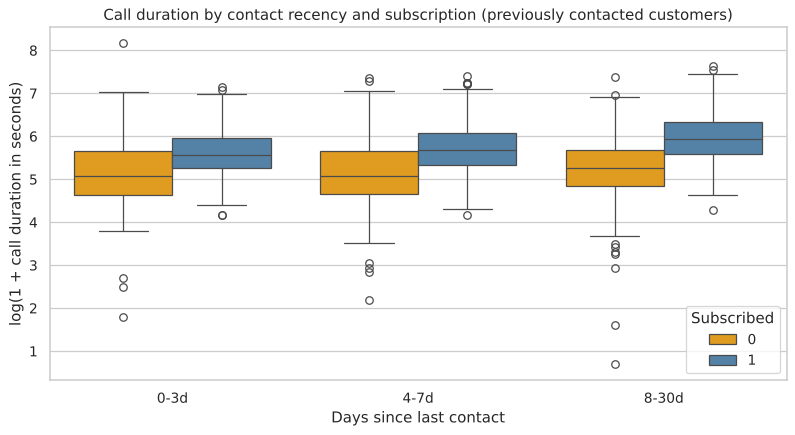

In [5]:
eda = df[df["pdays"] < 999].copy()   # a copy, so the main dataset is not changed
eda["recency_bin"] = pd.cut(eda["pdays"], bins=[-1, 3, 7, 30], labels=["0-3d", "4-7d", "8-30d"])

plt.figure(figsize=(9, 5))
sns.boxplot(data=eda, x="recency_bin", y=np.log1p(eda["duration"]), hue="y",
            palette={0: "orange", 1: "steelblue"})
for i, group in enumerate(["0-3d", "4-7d", "8-30d"]):
    g = eda[eda["recency_bin"] == group]
    t, p = ttest_ind(g.loc[g["y"] == 1, "duration"], g.loc[g["y"] == 0, "duration"], equal_var=False)
    print(f"{group}: Welch t-test p-value = {p:.4f}")
plt.title("Call duration by contact recency and subscription (previously contacted customers)")
plt.xlabel("Days since last contact"); plt.ylabel("log(1 + call duration in seconds)")
plt.legend(title="Subscribed")
plt.tight_layout(); plt.show()

Longer calls go with subscriptions. **However, `duration` is only known after the call has ended**, so it cannot be used to decide whom to call. It is used here for description only and is **excluded from the predictive model** (the dataset documentation gives the same advice).

### 5.2 Subscription rate by key categories

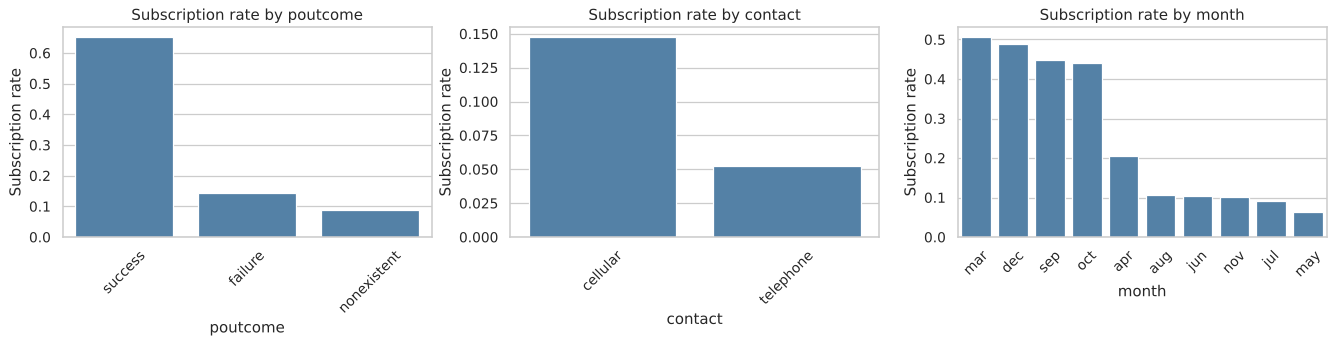

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["poutcome", "contact", "month"]):
    order = df.groupby(col)["y"].mean().sort_values(ascending=False).index
    sns.barplot(data=df, x=col, y="y", order=order, ax=ax, errorbar=None, color="steelblue")
    ax.set_title(f"Subscription rate by {col}"); ax.set_ylabel("Subscription rate")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

### 5.3 Correlation of numeric features with the target

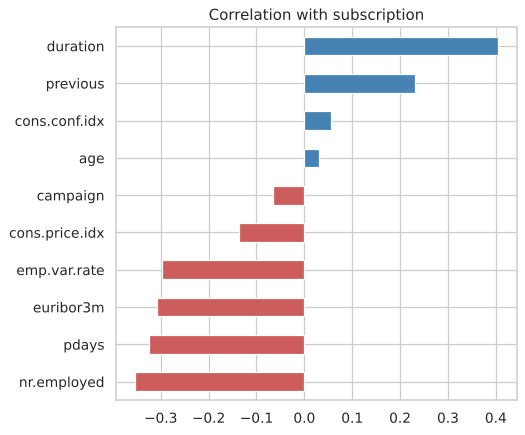

In [7]:
num_cols = df.select_dtypes("number").columns.drop("y")
corr = df[num_cols].corrwith(df["y"]).sort_values()
plt.figure(figsize=(6, 5))
corr.plot(kind="barh", color=np.where(corr > 0, "steelblue", "indianred"))
plt.title("Correlation with subscription"); plt.tight_layout(); plt.show()

## 6. Feature engineering

In [8]:
LEAKAGE = ["duration"]

df["previously_contacted"] = (df["pdays"] != 999).astype(int)
df["pdays_clean"] = np.where(df["pdays"] == 999, -1, df["pdays"])   # -1 = never contacted
df["age"] = df["age"].clip(upper=df["age"].quantile(0.99))          # cap extreme ages

categorical = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]
numeric = ["age", "campaign", "pdays_clean", "previously_contacted", "previous",
           "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

X = df[categorical + numeric]
y = df["y"]
print("Features used:", len(categorical) + len(numeric), "| excluded for leakage:", LEAKAGE)

Features used: 20 | excluded for leakage: ['duration']


## 7. Train/test split (before any scaling or resampling)

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Subscription rate train / test:", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

Train: (28823, 20) | Test: (12353, 20)
Subscription rate train / test: 0.113 / 0.113


## 8. Statistical feature screening (ANOVA F-test, training data only)

In [10]:
X_num = X_train[numeric]
f_vals, p_vals = f_classif(X_num, y_train)
anova = (pd.DataFrame({"Feature": numeric, "F-statistic": f_vals, "p-value": p_vals})
         .sort_values("F-statistic", ascending=False).reset_index(drop=True))
anova

,Feature,F-statistic,p-value
0,nr.employed,3988.708204,0.000000e+00
1,previously_contacted,3521.576910,0.000000e+00
2,euribor3m,2870.835682,0.000000e+00
3,emp.var.rate,2667.279620,0.000000e+00
4,pdays_clean,2450.979095,0.000000e+00
5,previous,1617.650536,0.000000e+00
6,cons.price.idx,489.915104,1.174918e-107
7,campaign,123.058654,1.546623e-28
8,cons.conf.idx,84.149814,4.883729e-20
9,age,18.964411,1.336386e-05


## 9. Modelling

All preprocessing sits inside a scikit-learn `Pipeline`, so the scaler and encoder are fitted on the **training data only**. Class imbalance is handled with `class_weight="balanced"`.

In [11]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                            n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", learning_rate=0.05,
                                                        max_iter=300, random_state=RANDOM_STATE),
}

rows, fitted, probs = [], {}, {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    fitted[name], probs[name] = pipe, p
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "ROC AUC": roc_auc_score(y_test, p),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred)})

results = pd.DataFrame(rows).sort_values("ROC AUC", ascending=False).reset_index(drop=True)
results.round(3)

,Model,Accuracy,ROC AUC,Precision,Recall,F1
0,Gradient Boosting,0.850,0.812,0.398,0.648,0.493
1,Random Forest,0.856,0.807,0.409,0.635,0.498
2,Logistic Regression,0.832,0.803,0.362,0.647,0.464
3,Decision Tree,0.854,0.794,0.403,0.620,0.488


Accuracy is not a good guide here: a model that predicts "no" for everyone would already reach about 89%. **ROC AUC and recall** are the metrics to compare.

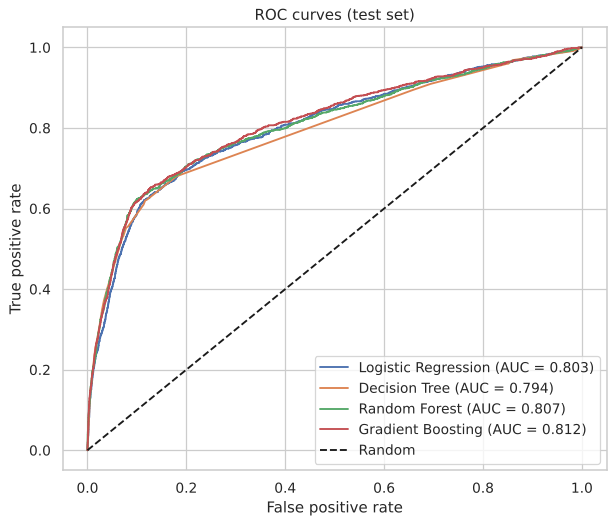

In [12]:
plt.figure(figsize=(7, 6))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves (test set)"); plt.legend(); plt.tight_layout(); plt.show()

## 10. Cross-validation of the best model

In [13]:
best_name = results.loc[0, "Model"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_auc = cross_val_score(Pipeline([("prep", preprocess), ("model", models[best_name])]),
                         X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
print(f"{best_name}: 5-fold CV ROC AUC = {cv_auc.mean():.3f} ± {cv_auc.std():.3f}")

Gradient Boosting: 5-fold CV ROC AUC = 0.799 ± 0.008


## 11. Confusion matrix (best model, threshold 0.5)

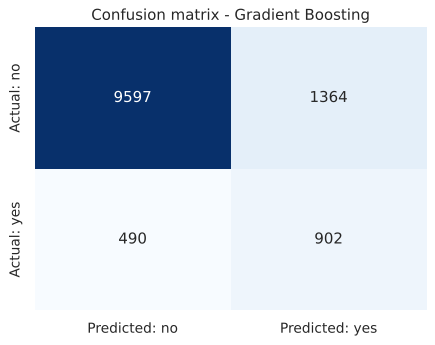

In [14]:
pred_best = (probs[best_name] >= 0.5).astype(int)
cm = pd.DataFrame(confusion_matrix(y_test, pred_best),
                  index=["Actual: no", "Actual: yes"], columns=["Predicted: no", "Predicted: yes"])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title(f"Confusion matrix - {best_name}"); plt.tight_layout(); plt.show()

## 12. Business impact: who should the call centre call first?

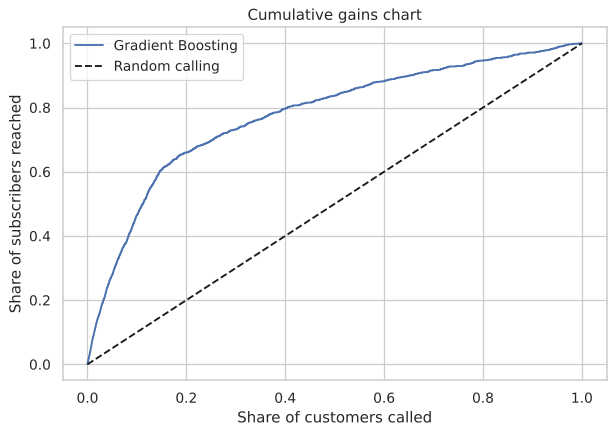

,Customers called (top-scored),Subscribers reached,Lift vs. random
0,10%,47%,4.66
1,20%,66%,3.30
2,30%,73%,2.44
3,50%,84%,1.68


In [15]:
scored = pd.DataFrame({"y": y_test.values, "score": probs[best_name]}).sort_values("score", ascending=False)
scored["share_called"] = np.arange(1, len(scored) + 1) / len(scored)
scored["share_subscribers_reached"] = scored["y"].cumsum() / scored["y"].sum()

lift_table = []
for share in [0.1, 0.2, 0.3, 0.5]:
    reached = scored.loc[scored["share_called"] <= share, "share_subscribers_reached"].iloc[-1]
    lift_table.append({"Customers called (top-scored)": f"{share:.0%}",
                       "Subscribers reached": f"{reached:.0%}",
                       "Lift vs. random": round(reached / share, 2)})
lift = pd.DataFrame(lift_table)

plt.figure(figsize=(7, 5))
plt.plot(scored["share_called"], scored["share_subscribers_reached"], label=best_name)
plt.plot([0, 1], [0, 1], "k--", label="Random calling")
plt.xlabel("Share of customers called"); plt.ylabel("Share of subscribers reached")
plt.title("Cumulative gains chart"); plt.legend(); plt.tight_layout(); plt.show()
lift

## 13. What drives subscription? (permutation importance)

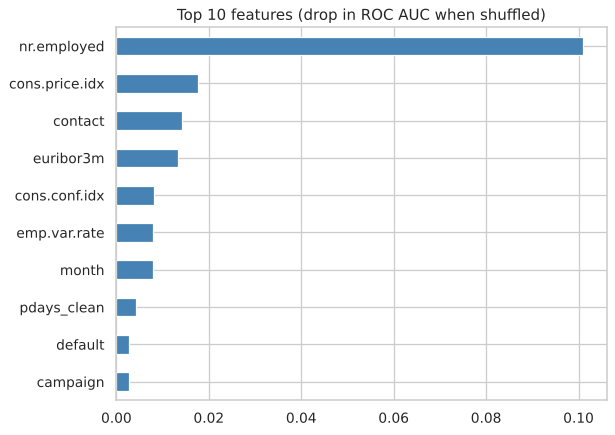

In [16]:
from sklearn.inspection import permutation_importance
imp = permutation_importance(fitted[best_name], X_test, y_test, scoring="roc_auc",
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
importance = (pd.Series(imp.importances_mean, index=X_test.columns)
              .sort_values(ascending=False).head(10))
plt.figure(figsize=(7, 5))
importance.sort_values().plot(kind="barh", color="steelblue")
plt.title("Top 10 features (drop in ROC AUC when shuffled)"); plt.tight_layout(); plt.show()

## 14. Why `duration` was excluded: leakage check

In [17]:
pipe_leak = Pipeline([
    ("prep", ColumnTransformer([("num", StandardScaler(), numeric + ["duration"]),
                                ("cat", OneHotEncoder(handle_unknown="ignore"), categorical)])),
    ("model", models[best_name])])
Xl_train, Xl_test = df.loc[X_train.index, categorical + numeric + ["duration"]], df.loc[X_test.index, categorical + numeric + ["duration"]]
pipe_leak.fit(Xl_train, y_train)
auc_leak = roc_auc_score(y_test, pipe_leak.predict_proba(Xl_test)[:, 1])
print(f"ROC AUC with duration (not usable before a call): {auc_leak:.3f}")
print(f"ROC AUC without duration (realistic):            {results.loc[0, 'ROC AUC']:.3f}")

ROC AUC with duration (not usable before a call): 0.949
ROC AUC without duration (realistic):            0.812


Including `duration` makes the model look much better, but only because it uses information that does not exist when the bank decides whom to call. The realistic model is the one reported above.

## 15. Optional: SMOTE-ENN resampling (needs `pip install imbalanced-learn`)

In [18]:
try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.combine import SMOTEENN
    smote_pipe = ImbPipeline([("prep", preprocess),
                              ("resample", SMOTEENN(sampling_strategy=0.7, random_state=RANDOM_STATE)),
                              ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                               n_jobs=-1, random_state=RANDOM_STATE))])
    smote_pipe.fit(X_train, y_train)          # resampling happens on training data only
    p = smote_pipe.predict_proba(X_test)[:, 1]
    print(f"Random Forest + SMOTE-ENN: ROC AUC = {roc_auc_score(y_test, p):.3f}, "
          f"recall = {recall_score(y_test, (p >= 0.5).astype(int)):.3f}")
except ImportError:
    print("imbalanced-learn is not installed; skipping the SMOTE-ENN comparison.")

imbalanced-learn is not installed; skipping the SMOTE-ENN comparison.


## 16. Conclusions

- **Best realistic model:** Gradient Boosting, ROC AUC 0.81 on the test set (5-fold CV 0.80 ± 0.01) with 65% recall of subscribers. Including the leaky `duration` feature would have inflated AUC to 0.95.
- **Business value:** calling the top 20% of customers ranked by the model reaches about 66% of all subscribers, 3.3 times better than random calling. The top 10% alone reaches about 47%.
- **Main drivers:** the economic climate (number of employees, consumer price index, Euribor rate), contact channel (cellular better than telephone), month of contact and previous campaign outcome.
- **Recommendation:** prioritise call lists by model score, prefer mobile contact, and plan campaign volume around the economic indicators.
- **Limitations:** a single bank and period (2008-2010); the threshold of 0.5 could be tuned to the call centre's capacity and cost per call.